# QPE

Implementing QPE as a function

In [1]:
from numpy import pi
from qiskit import ClassicalRegister, QuantumRegister, QuantumCircuit
from qiskit.circuit.library import QFTGate
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

In [2]:
def qpe(
        theta,
        prep_gates=("x",),
        n_count: int = 3,
        shots: int = 2048,
        sim: AerSimulator | None = None,
) -> dict:
    """Estimate Eigen Phase Theta"""

    counting = QuantumRegister(n_count, "count")
    target = QuantumRegister(1, "target")
    c_out = ClassicalRegister(n_count, "meas")
    qc = QuantumCircuit(counting, target, c_out)

    if sim is None:
        sim = AerSimulator()

    # Compose psi
    for g in prep_gates:
        getattr(qc, g)(target[0])

    # Apply Hadamard
    for q in counting:
        qc.h(q)

    # Controlled U - Phase Kickback
    reps = 1
    for q in counting:
        for _ in range(reps):
            qc.cp(2 * pi * theta, q, target[0])
        reps *= 2

    # Inverse QFT
    qc.append(QFTGate(n_count).inverse(), counting)
    qc.measure(counting, c_out)

    # Decompose gate
    counts = sim.run(qc.decompose(reps=3), shots=shots).result().get_counts()

    top_bitstring = max(counts, key=counts.get)
    estimated_theta = int(top_bitstring, 2) / (2**n_count)

    return {
        "circuit": qc,
        "counts": counts,
        "top_bitstring": top_bitstring,
        "estimated_theta": estimated_theta,
    }


Actual thita = 0.125
Top bitstring: 001 -> estimated theta = 0.125


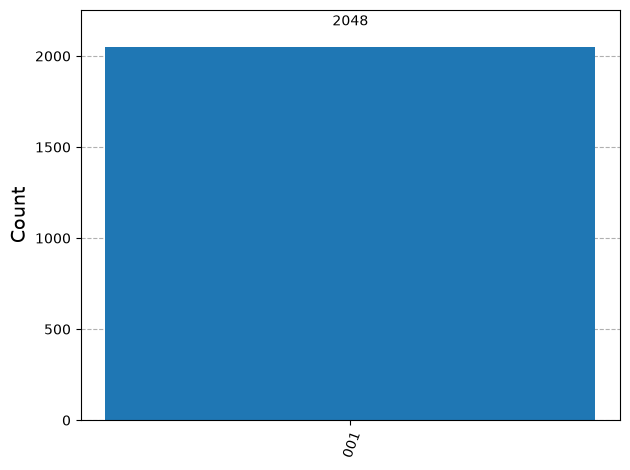

In [3]:
# Run QPE in T gate

theta = 1/8

out = qpe(theta, prep_gates=("x",), n_count=3, shots=2048)
print(f"Actual thita = {theta}")
print(
    f"Top bitstring: {out['top_bitstring']} -> estimated theta ="
    f" {out['estimated_theta']}"
)

plot_histogram(out["counts"])

Actual thita = 0.3333333333333333
Top bitstring: 011 -> estimated theta = 0.375


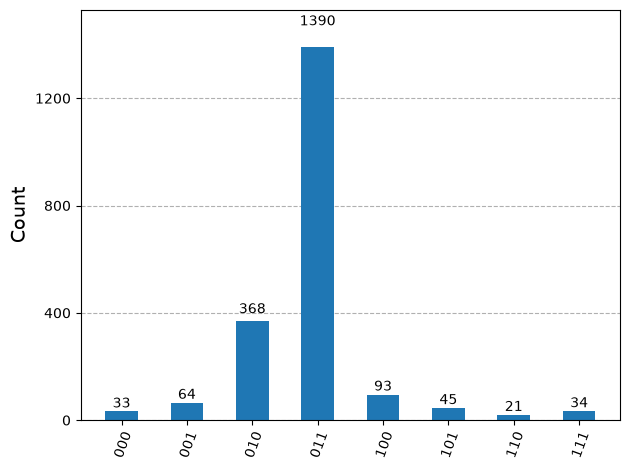

In [4]:
# Run QPE for theta = 1/3

theta = 1/3

out = qpe(theta, prep_gates=("x",), n_count=3, shots=2048)
print(f"Actual thita = {theta}")
print(
    f"Top bitstring: {out['top_bitstring']} -> estimated theta ="
    f" {out['estimated_theta']}"
)

plot_histogram(out["counts"])

Actual thita = 0.3333333333333333
Top bitstring: 01011 -> estimated theta = 0.34375


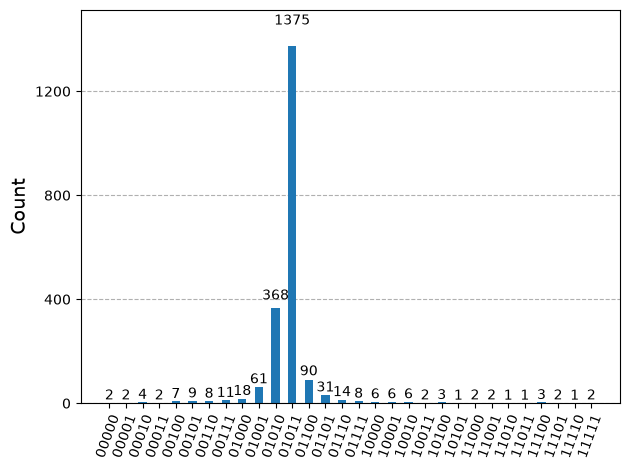

In [5]:
# Run QPE for theta = 1/3, with increased number of qubit
# Higher qubit -> more accurate

theta = 1/3

out = qpe(theta, prep_gates=("x",), n_count=5, shots=2048)
print(f"Actual thita = {theta}")
print(
    f"Top bitstring: {out['top_bitstring']} -> estimated theta ="
    f" {out['estimated_theta']}"
)

plot_histogram(out["counts"])

raw bitstring: 100 -> theta = 0.125


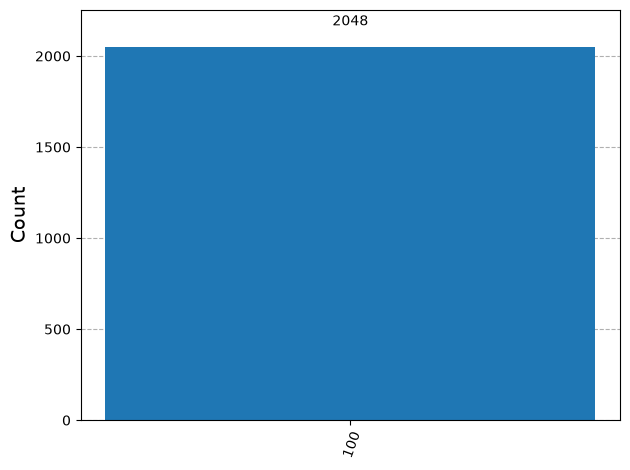

In [6]:
# Using standard library

from qiskit.circuit.library import PhaseGate, phase_estimation, TGate

n = 3
qc = QuantumCircuit(n + 1, n)
qc.x(n)
qc.compose(phase_estimation(n, TGate()), inplace=True)
qc.measure(range(n), range(n))

counts = (
    AerSimulator()
    .run(qc.decompose(reps=3), shots=2048)
    .result()
    .get_counts()
)

best = max(counts, key=counts.get)

# Here need to reverse the bitstring
theta = int(best[::-1], 2) / (2**n)

print("raw bitstring:", best, "-> theta =", theta)

plot_histogram(counts)

raw bitstring: 110 -> theta = 0.375


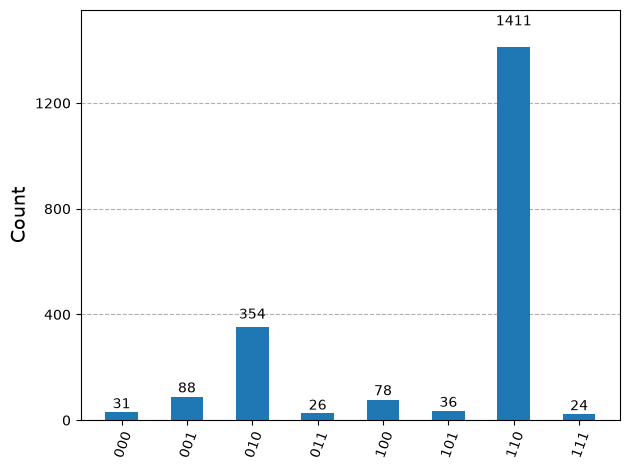

In [7]:
# Using standard library

from qiskit.circuit.library import PhaseGate, phase_estimation, TGate

n = 3
qc = QuantumCircuit(n + 1, n)
qc.x(n)
qc.compose(phase_estimation(n, PhaseGate(2*pi*(1/3))), inplace=True)
qc.measure(range(n), range(n))

counts = (
    AerSimulator()
    .run(qc.decompose(reps=3), shots=2048)
    .result()
    .get_counts()
)

best = max(counts, key=counts.get)
theta = int(best[::-1], 2) / (2**n)
print("raw bitstring:", best, "-> theta =", theta)

plot_histogram(counts)